# Fake News / Misinformation Detection using a Deterministic Finite Automaton (DFA)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/fake-news-dfa-detector/blob/main/fake_news_detection.ipynb)

**Course:** Theory of Computation / Automata Theory &nbsp;|&nbsp; **Language:** Python 3 &nbsp;|&nbsp; **Library:** pandas

This notebook runs the complete mini-project from start to finish:

1. Install / import the required packages
2. Understand the DFA that is used for detection
3. Build the DFA in Python (states, alphabet, transitions, start state, accepting state)
4. Load the labelled dataset with **pandas**
5. Evaluate the DFA on the dataset
6. Classify new headlines and **explain every step** (keywords, state transitions, final state, prediction)

> **How to use:** click **Runtime -> Run all**. Change the headline in the *"Try your own headline"* cell
> to test your own text.

## 1. Setup - install the required packages

Google Colab already ships with `pandas` and `matplotlib`, so this cell normally finishes instantly.
It is kept so that the notebook also works on a fresh machine.

In [1]:
%pip install -q --disable-pip-version-check pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. What is a DFA?

A **Deterministic Finite Automaton** is an abstract machine defined by the 5-tuple

$$M = (Q,\ \Sigma,\ \delta,\ q_0,\ F)$$

| Symbol | Meaning | In this project |
|---|---|---|
| $Q$ | finite set of states | `q0, q1, q2, q3, q4` |
| $\Sigma$ | input alphabet | `S, C, U, R, N` |
| $\delta : Q \times \Sigma \to Q$ | transition function (exactly one move for every state/symbol pair) | the table below |
| $q_0$ | start state | `q0` |
| $F \subseteq Q$ | accepting states | `{q3}` = **FAKE** |

The machine reads a string symbol by symbol, always moving to exactly one next state.
If it ends in an accepting state the input is **accepted**; here, *accepted = flagged as Fake*.

### How a headline becomes an input string

Every word (or phrase) of the headline is converted into one alphabet symbol:

| Symbol | Meaning | Examples |
|---|---|---|
| **S** | Sensational / exaggerated wording | shocking, miracle, secret, 100%, `!` |
| **C** | Clickbait / conspiracy phrase | hoax, cover-up, doctors hate, you won't believe |
| **U** | Urgency / share-bait (strong signal) | share this, forward this, urgent, before it's deleted |
| **R** | Credibility marker (attribution to a source) | according to, officials, study, ministry, said |
| **N** | Neutral word | every other word |

### The states

| State | Meaning |
|---|---|
| `q0` | **Start / neutral** - no net suspicious signal |
| `q1` | **Low suspicion** - one suspicious signal |
| `q2` | **High suspicion** - two signals (borderline, still *Real*) |
| `q3` | **FAKE** - accepting and absorbing: once reached, it can never be left |
| `q4` | **Credible** - a credibility marker was seen |

### The transition function $\delta$

| state | S | C | U | R | N |
|---|---|---|---|---|---|
| **q0** | q1 | q1 | q2 | q4 | q0 |
| **q1** | q2 | q2 | q3 | q0 | q1 |
| **q2** | q3 | q3 | q3 | q1 | q2 |
| **q3** | q3 | q3 | q3 | q3 | q3 |
| **q4** | q0 | q0 | q1 | q4 | q4 |

*Idea:* S / C move one step towards `q3`, **U** moves two steps, **R** moves one step back, **N** never changes the state.

## 3. Import the libraries

In [2]:
# =============================================================================
# SECTION 1: IMPORTS
# =============================================================================
import math
import re
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import pandas as pd
from IPython.display import display

## 4. Define the alphabet, states, transitions and keyword lexicon

All parts of the DFA are stored as plain Python data so that they are easy to read and modify.

In [3]:
# =============================================================================
# SECTION 2: DFA DEFINITION DATA (alphabet, states, transitions, lexicon)
# =============================================================================

# --- Input alphabet (Sigma) --------------------------------------------------
# Every word (or phrase) of a headline is converted into exactly one of these
# symbols before it is fed to the DFA.
SYM_SENSATIONAL = "S"   # exaggerated / emotional wording
SYM_CLICKBAIT = "C"     # clickbait or conspiracy phrase
SYM_URGENCY = "U"       # urgency / "share this now" pressure
SYM_CREDIBLE = "R"      # credibility marker (attribution to a source)
SYM_NEUTRAL = "N"       # any other, ordinary word

ALPHABET: Tuple[str, ...] = (
    SYM_SENSATIONAL,
    SYM_CLICKBAIT,
    SYM_URGENCY,
    SYM_CREDIBLE,
    SYM_NEUTRAL,
)

SYMBOL_DESCRIPTIONS: Dict[str, str] = {
    SYM_SENSATIONAL: "Sensational / exaggerated wording",
    SYM_CLICKBAIT: "Clickbait / conspiracy phrase",
    SYM_URGENCY: "Urgency / share-bait",
    SYM_CREDIBLE: "Credibility marker (source / attribution)",
    SYM_NEUTRAL: "Neutral word (no signal)",
}

# --- States (Q) --------------------------------------------------------------
STATE_START = "q0"      # start state, no net suspicious signal
STATE_LOW = "q1"        # one suspicious signal
STATE_HIGH = "q2"       # two suspicious signals (borderline)
STATE_FAKE = "q3"       # accepting state: suspicion threshold reached
STATE_CREDIBLE = "q4"   # a credibility marker was seen

STATE_DESCRIPTIONS: Dict[str, str] = {
    STATE_START: "START / NEUTRAL - no net suspicious signal",
    STATE_LOW: "LOW SUSPICION - one suspicious signal",
    STATE_HIGH: "HIGH SUSPICION - two signals (borderline, still Real)",
    STATE_FAKE: "FAKE - suspicion threshold reached (accepting, absorbing)",
    STATE_CREDIBLE: "CREDIBLE - credibility marker seen",
}

ACCEPTING_STATES = frozenset({STATE_FAKE})

# --- Transition function (delta) --------------------------------------------
# TRANSITION_TABLE[current_state][input_symbol] = next_state
#
# Intuition:
#   * S / C push the automaton one step towards FAKE,
#   * U (urgency) is a stronger signal and pushes it two steps,
#   * R (credibility) pulls it back one step (or into the CREDIBLE state),
#   * N (neutral) never changes the state (self-loop),
#   * q3 (FAKE) is absorbing: once reached it can never be left.
TRANSITION_TABLE: Dict[str, Dict[str, str]] = {
    #        S      C      U      R      N
    "q0": {"S": "q1", "C": "q1", "U": "q2", "R": "q4", "N": "q0"},
    "q1": {"S": "q2", "C": "q2", "U": "q3", "R": "q0", "N": "q1"},
    "q2": {"S": "q3", "C": "q3", "U": "q3", "R": "q1", "N": "q2"},
    "q3": {"S": "q3", "C": "q3", "U": "q3", "R": "q3", "N": "q3"},
    "q4": {"S": "q0", "C": "q0", "U": "q1", "R": "q4", "N": "q4"},
}

# --- Lexicon: words / phrases that map to each non-neutral symbol -----------
# Phrases are matched word-by-word (longest phrase first). Apostrophes and
# hyphens are ignored, so "don't" is written "dont" and "cover-up" "cover up".
LEXICON: Dict[str, Tuple[str, ...]] = {
    SYM_SENSATIONAL: (
        "shocking", "unbelievable", "miracle", "miraculous", "secret", "secrets",
        "exposed", "exposes", "bombshell", "stunning", "horrifying",
        "mind blowing", "jaw dropping", "100%", "guaranteed", "instantly",
        "cures", "cure all", "overnight", "!",
    ),
    SYM_CLICKBAIT: (
        "hoax", "conspiracy", "cover up", "coverup", "covered up", "covering up",
        "covering it up", "illuminati", "chemtrails", "big pharma",
        "mainstream media", "deep state", "new world order", "mind control",
        "doctors hate", "you wont believe", "dont want you to know",
        "wont tell you", "hidden truth", "hiding the truth", "the truth about",
        "wake up",
    ),
    SYM_URGENCY: (
        "urgent", "share this", "share now", "share with everyone",
        "forward this", "spread the word", "tell everyone", "must watch",
        "must share", "before its deleted", "before they delete",
        "before it gets deleted", "send this to", "retweet",
    ),
    SYM_CREDIBLE: (
        "according to", "officials", "official", "ministry", "announced",
        "announces", "announce", "reported", "reports", "report", "researchers",
        "study", "published", "confirmed", "confirms", "spokesperson",
        "statement", "survey", "university", "court", "parliament",
        "commission", "statistics", "percent", "data shows", "said", "says",
    ),
}

# Sample headlines used by the demo mode / notebook (not part of dataset.csv).
SAMPLE_HEADLINES: Tuple[str, ...] = (
    "SHOCKING secret cure exposed! Share this before it's deleted",
    "Government announces new metro line, officials said",
    "Researchers publish study on air pollution in Indian cities",
    "Miracle weight loss pill guaranteed to work, doctors hate it",
    "Shocking rise in onion prices worries shoppers, ministry reports",
    "Local school wins state level football tournament",
)

LABELS: Tuple[str, str] = ("Fake", "Real")
MAX_HEADLINE_LENGTH = 300
MIN_HEADLINE_WORDS = 3
QUIT_COMMANDS = ("quit", "exit", "q")

## 5. Text processing

Three small functions turn a raw headline into a sequence of DFA input symbols:

* `normalize_text` - lower-case, remove punctuation
* `validate_headline` - reject empty / invalid input (the program never crashes on bad input)
* `tokenize` - longest-match scan of the lexicon; unknown words become `N`

In [4]:
# =============================================================================
# SECTION 3: TEXT PROCESSING (validation, normalisation, tokenisation)
# =============================================================================
class InvalidHeadlineError(ValueError):
    """Raised when a headline cannot be processed (empty, too short, etc.)."""


@dataclass(frozen=True)
class Token:
    """A word or phrase of the headline together with its DFA input symbol."""

    text: str     # the (normalised) word or phrase that was matched
    symbol: str   # one of the symbols in ALPHABET


def normalize_text(text: str) -> str:
    """Convert a headline to a clean, lower-case form that is easy to tokenise.

    * lower-cases everything,
    * removes apostrophes ("don't" -> "dont"),
    * turns runs of "!" into a single stand-alone "!" token,
    * replaces every other punctuation mark (including hyphens) with a space,
    * collapses repeated whitespace.
    """
    text = text.lower()
    text = re.sub(r"['\u2018\u2019`]", "", text)    # drop apostrophes
    text = re.sub(r"!+", " ! ", text)               # "!!!" -> single "!" token
    text = re.sub(r"[^a-z0-9%!\s]", " ", text)      # punctuation / hyphens -> space
    return re.sub(r"\s+", " ", text).strip()


def validate_headline(headline: object) -> str:
    """Check that the user input is usable and return the stripped headline.

    Raises:
        InvalidHeadlineError: if the input is not text, is empty, too long,
            has no English letters, or has fewer than MIN_HEADLINE_WORDS words.
    """
    if not isinstance(headline, str):
        raise InvalidHeadlineError("The headline must be text.")

    cleaned = headline.strip()
    if not cleaned:
        raise InvalidHeadlineError("The headline is empty. Please type a news headline.")
    if len(cleaned) > MAX_HEADLINE_LENGTH:
        raise InvalidHeadlineError(
            f"The headline is too long ({len(cleaned)} characters). "
            f"Maximum allowed is {MAX_HEADLINE_LENGTH}."
        )
    if not re.search(r"[A-Za-z]", cleaned):
        raise InvalidHeadlineError("The headline must contain English letters, not only digits or symbols.")

    word_count = len(re.findall(r"[a-z0-9%]+", normalize_text(cleaned)))
    if word_count < MIN_HEADLINE_WORDS:
        raise InvalidHeadlineError(
            f"The headline is too short ({word_count} word(s)). "
            f"Please enter at least {MIN_HEADLINE_WORDS} words."
        )
    return cleaned


def build_phrase_index(lexicon: Dict[str, Tuple[str, ...]]) -> List[Tuple[Tuple[str, ...], str]]:
    """Turn the lexicon into a list of (phrase_words, symbol), longest phrase first.

    Sorting by length makes the tokenizer prefer "share this" over a shorter
    match, i.e. it performs *longest-match* scanning.
    """
    index: List[Tuple[Tuple[str, ...], str]] = []
    seen: Dict[Tuple[str, ...], str] = {}
    for symbol, phrases in lexicon.items():
        for phrase in phrases:
            words = tuple(normalize_text(phrase).split())
            if words in seen:
                raise ValueError(f"Lexicon conflict: '{phrase}' appears under both {seen[words]} and {symbol}.")
            seen[words] = symbol
            index.append((words, symbol))
    index.sort(key=lambda item: len(item[0]), reverse=True)
    return index


# Built once at import time and re-used for every headline.
PHRASE_INDEX = build_phrase_index(LEXICON)


def tokenize(headline: str, phrase_index: Optional[List[Tuple[Tuple[str, ...], str]]] = None) -> List[Token]:
    """Split a headline into tokens and assign each one a DFA input symbol.

    Words that are not found in the lexicon become neutral tokens (symbol N).
    """
    phrase_index = PHRASE_INDEX if phrase_index is None else phrase_index
    words = normalize_text(headline).split()

    tokens: List[Token] = []
    position = 0
    while position < len(words):
        for phrase_words, symbol in phrase_index:
            end = position + len(phrase_words)
            if tuple(words[position:end]) == phrase_words:
                tokens.append(Token(" ".join(phrase_words), symbol))
                position = end
                break
        else:  # no lexicon phrase starts here -> ordinary word
            tokens.append(Token(words[position], SYM_NEUTRAL))
            position += 1
    return tokens

## 6. The DFA engine

The `DFA` class is completely generic: it stores `Q`, `Sigma`, `delta`, `q0`, `F`, checks that the table is
**complete and deterministic** (`validate`) and runs a string through the machine (`run`).
`build_news_dfa()` creates our fake-news automaton from the data defined above.

In [5]:
# =============================================================================
# SECTION 4: THE DFA ENGINE
# =============================================================================
class DFA:
    """A generic Deterministic Finite Automaton M = (Q, Sigma, delta, q0, F).

    The class knows nothing about news: it only stores the five components and
    runs a sequence of symbols through the transition function.
    """

    def __init__(
        self,
        states: Sequence[str],
        alphabet: Sequence[str],
        transitions: Dict[Tuple[str, str], str],
        start_state: str,
        accepting_states: Sequence[str],
        state_descriptions: Optional[Dict[str, str]] = None,
    ) -> None:
        self.states: Tuple[str, ...] = tuple(states)
        self.alphabet: Tuple[str, ...] = tuple(alphabet)
        self.transitions: Dict[Tuple[str, str], str] = dict(transitions)
        self.start_state: str = start_state
        self.accepting_states: frozenset = frozenset(accepting_states)
        self.state_descriptions: Dict[str, str] = dict(state_descriptions or {})
        self.validate()

    def validate(self) -> None:
        """Make sure the five components really form a valid (complete) DFA."""
        if len(set(self.states)) != len(self.states):
            raise ValueError("DFA states must be unique.")
        if len(set(self.alphabet)) != len(self.alphabet):
            raise ValueError("DFA alphabet symbols must be unique.")
        if self.start_state not in self.states:
            raise ValueError(f"Start state '{self.start_state}' is not in the set of states.")
        if not self.accepting_states.issubset(self.states):
            raise ValueError("Every accepting state must be a member of the set of states.")

        # A DFA needs exactly ONE transition for every (state, symbol) pair.
        for state in self.states:
            for symbol in self.alphabet:
                if (state, symbol) not in self.transitions:
                    raise ValueError(f"Missing transition for ({state}, {symbol}).")
        for (state, symbol), target in self.transitions.items():
            if state not in self.states or symbol not in self.alphabet or target not in self.states:
                raise ValueError(f"Invalid transition ({state}, {symbol}) -> {target}.")

    def step(self, state: str, symbol: str) -> str:
        """Apply the transition function delta(state, symbol)."""
        if symbol not in self.alphabet:
            raise ValueError(f"Symbol '{symbol}' is not in the DFA alphabet {self.alphabet}.")
        return self.transitions[(state, symbol)]

    def run(self, symbols: Sequence[str]) -> Tuple[str, List[Tuple[str, str, str]]]:
        """Feed all symbols to the DFA.

        Returns:
            (final_state, path) where path is a list of
            (source_state, symbol, target_state) triples, one per symbol.
        """
        state = self.start_state
        path: List[Tuple[str, str, str]] = []
        for symbol in symbols:
            next_state = self.step(state, symbol)
            path.append((state, symbol, next_state))
            state = next_state
        return state, path

    def accepts(self, symbols: Sequence[str]) -> bool:
        """True if the DFA ends in an accepting state after reading symbols."""
        final_state, _ = self.run(symbols)
        return final_state in self.accepting_states


def build_news_dfa() -> DFA:
    """Create the fake-news DFA from the constants in SECTION 2."""
    transitions = {
        (state, symbol): target
        for state, row in TRANSITION_TABLE.items()
        for symbol, target in row.items()
    }
    return DFA(
        states=sorted(TRANSITION_TABLE),
        alphabet=ALPHABET,
        transitions=transitions,
        start_state=STATE_START,
        accepting_states=ACCEPTING_STATES,
        state_descriptions=STATE_DESCRIPTIONS,
    )


def transition_table(dfa: DFA) -> pd.DataFrame:
    """Return delta as a pandas DataFrame (rows = states, columns = symbols)."""
    data = {
        symbol: [dfa.transitions[(state, symbol)] for state in dfa.states]
        for symbol in dfa.alphabet
    }
    table = pd.DataFrame(data, index=list(dfa.states))
    table.index.name = "state"
    return table

## 7. Detection and reporting

`detect()` connects everything: *validate -> tokenise -> run the DFA -> Fake / Real*.
`format_report()` prints, **in this order**: detected keywords, state transitions, final DFA state, prediction.

In [6]:
# =============================================================================
# SECTION 5: DETECTION (headline -> prediction)
# =============================================================================
@dataclass(frozen=True)
class Transition:
    """One step of the DFA run, kept for the explanation shown to the user."""

    step: int       # 1-based position in the token stream
    token: str      # word / phrase that was read
    symbol: str     # DFA input symbol
    source: str     # state before reading the symbol
    target: str     # state after reading the symbol


@dataclass(frozen=True)
class Prediction:
    """Everything produced while classifying one headline."""

    headline: str
    tokens: Tuple[Token, ...]
    transitions: Tuple[Transition, ...]
    final_state: str
    is_fake: bool

    @property
    def label(self) -> str:
        """'Fake' if the DFA stopped in an accepting state, otherwise 'Real'."""
        return "Fake" if self.is_fake else "Real"

    @property
    def keywords(self) -> List[Token]:
        """Only the tokens that carry a signal (everything except neutral words)."""
        return [token for token in self.tokens if token.symbol != SYM_NEUTRAL]


def detect(headline: str, dfa: Optional[DFA] = None) -> Prediction:
    """Classify a headline as Fake or Real using the DFA.

    Raises:
        InvalidHeadlineError: if the headline fails validation.
    """
    dfa = dfa or build_news_dfa()
    cleaned = validate_headline(headline)

    tokens = tokenize(cleaned)
    final_state, path = dfa.run([token.symbol for token in tokens])

    transitions = tuple(
        Transition(step=index, token=token.text, symbol=symbol, source=source, target=target)
        for index, (token, (source, symbol, target)) in enumerate(zip(tokens, path), start=1)
    )
    return Prediction(
        headline=cleaned,
        tokens=tuple(tokens),
        transitions=transitions,
        final_state=final_state,
        is_fake=final_state in dfa.accepting_states,
    )

In [7]:
# =============================================================================
# SECTION 6: REPORTING (pretty text output)
# =============================================================================
REPORT_WIDTH = 72


def format_dfa_definition(dfa: DFA) -> str:
    """Return a readable description of the DFA (states, alphabet, delta ...)."""
    lines = [
        "=" * REPORT_WIDTH,
        "DFA DEFINITION   M = (Q, Sigma, delta, q0, F)",
        "=" * REPORT_WIDTH,
        f"Q (states)          : {{{', '.join(dfa.states)}}}",
        f"Sigma (alphabet)    : {{{', '.join(dfa.alphabet)}}}",
        f"q0 (start state)    : {dfa.start_state}",
        f"F (accepting states): {{{', '.join(sorted(dfa.accepting_states))}}}",
        "",
        "States:",
    ]
    for state in dfa.states:
        lines.append(f"  {state} : {dfa.state_descriptions.get(state, '')}")
    lines.append("")
    lines.append("Alphabet symbols:")
    for symbol in dfa.alphabet:
        lines.append(f"  {symbol} : {SYMBOL_DESCRIPTIONS.get(symbol, '')}")
    lines.append("")
    lines.append("Transition function delta (row = current state, column = input symbol):")
    lines.append(transition_table(dfa).to_string())
    lines.append("=" * REPORT_WIDTH)
    return "\n".join(lines)


def format_report(prediction: Prediction, dfa: DFA, show_neutral: bool = False) -> str:
    """Build the explanation for one headline.

    Order of the report (as required by the project specification):
        1. detected keywords
        2. DFA state transitions
        3. final DFA state
        4. the prediction
    """
    lines = [
        "=" * REPORT_WIDTH,
        f"HEADLINE: {prediction.headline}",
        "=" * REPORT_WIDTH,
        "STEP 1 - Detected keywords",
    ]

    # --- Step 1: keywords ---------------------------------------------------
    if prediction.keywords:
        for number, token in enumerate(prediction.keywords, start=1):
            meaning = SYMBOL_DESCRIPTIONS[token.symbol]
            lines.append(f'  {number}. "{token.text}"  ->  {token.symbol}  ({meaning})')
    else:
        lines.append("  (none - every word in this headline is neutral)")

    # --- Step 2: state transitions -----------------------------------------
    lines.append("")
    lines.append(f"STEP 2 - DFA state transitions (start state = {dfa.start_state})")
    hidden_neutral = 0
    for move in prediction.transitions:
        if move.symbol == SYM_NEUTRAL and not show_neutral:
            hidden_neutral += 1   # neutral words only cause self-loops
            continue
        lines.append(
            f'  [{move.step:>2}] {move.source} --{move.symbol}--> {move.target}'
            f'    (read "{move.token}")'
        )
    if hidden_neutral:
        lines.append(f"  ...  {hidden_neutral} neutral word(s) caused self-loops (hidden; use verbose mode to show)")

    # --- Step 3: final state -----------------------------------------------
    is_accepting = prediction.final_state in dfa.accepting_states
    lines.append("")
    lines.append("STEP 3 - Final DFA state")
    lines.append(f"  Final state     : {prediction.final_state}")
    lines.append(f"  Meaning         : {dfa.state_descriptions.get(prediction.final_state, '')}")
    lines.append(f"  Accepting state : {'YES' if is_accepting else 'NO'}")

    # --- Step 4: prediction -------------------------------------------------
    lines.append("-" * REPORT_WIDTH)
    reason = "accepting" if is_accepting else "non-accepting"
    lines.append(f"PREDICTION: {prediction.label.upper()}   (DFA ended in {reason} state {prediction.final_state})")
    lines.append("=" * REPORT_WIDTH)
    return "\n".join(lines)


def print_report(prediction: Prediction, dfa: DFA, show_neutral: bool = False) -> None:
    """Print the report returned by format_report()."""
    print(format_report(prediction, dfa, show_neutral=show_neutral))


def interactive_mode(dfa: DFA, show_neutral: bool = False) -> None:
    """Keep asking the user for headlines until they type 'quit' (or press Ctrl+C)."""
    print("\nINTERACTIVE MODE - type a news headline and press Enter.")
    print("Type 'quit' to stop.")
    while True:
        try:
            text = input("\nEnter a news headline: ")
        except (EOFError, KeyboardInterrupt):
            print("\nInput closed. Goodbye!")
            return
        if text.strip().lower() in QUIT_COMMANDS:
            print("Goodbye!")
            return
        try:
            prediction = detect(text, dfa)
        except InvalidHeadlineError as error:
            print(f"[Invalid input] {error}")
            continue
        print_report(prediction, dfa, show_neutral=show_neutral)

## 8. Create the DFA and inspect it

In [8]:
dfa = build_news_dfa()              # also validates that the DFA is complete and deterministic
print(format_dfa_definition(dfa))

DFA DEFINITION   M = (Q, Sigma, delta, q0, F)
Q (states)          : {q0, q1, q2, q3, q4}
Sigma (alphabet)    : {S, C, U, R, N}
q0 (start state)    : q0
F (accepting states): {q3}

States:
  q0 : START / NEUTRAL - no net suspicious signal
  q1 : LOW SUSPICION - one suspicious signal
  q2 : HIGH SUSPICION - two signals (borderline, still Real)
  q3 : FAKE - suspicion threshold reached (accepting, absorbing)
  q4 : CREDIBLE - credibility marker seen

Alphabet symbols:
  S : Sensational / exaggerated wording
  C : Clickbait / conspiracy phrase
  U : Urgency / share-bait
  R : Credibility marker (source / attribution)
  N : Neutral word (no signal)

Transition function delta (row = current state, column = input symbol):
        S   C   U   R   N
state                    
q0     q1  q1  q2  q4  q0
q1     q2  q2  q3  q0  q1
q2     q3  q3  q3  q1  q2
q3     q3  q3  q3  q3  q3
q4     q0  q0  q1  q4  q4


### State diagram

Double circle = accepting state (`q3`, FAKE). Red arrows lead into the FAKE state.

In [9]:
# =============================================================================
# SECTION 8: DFA DIAGRAM (matplotlib, optional)
# =============================================================================
# Hand-tuned node positions for the 5-state fake-news DFA (x, y).
_NODE_POSITIONS: Dict[str, Tuple[float, float]] = {
    "q0": (0.0, 0.0),
    "q1": (4.6, 0.0),
    "q2": (9.2, 0.0),
    "q3": (13.8, 0.0),
    "q4": (0.0, -3.6),
}
# Short caption written under every state in the diagram.
_NODE_CAPTIONS: Dict[str, str] = {
    "q0": "START", "q1": "LOW", "q2": "HIGH", "q3": "FAKE", "q4": "CREDIBLE",
}
# Direction (degrees) in which each self-loop is drawn.
_LOOP_ANGLES: Dict[str, float] = {"q0": 90, "q1": 90, "q2": 90, "q3": 90, "q4": 180}
# Curvature of the arrows between states (positive bends below for left->right).
_EDGE_CURVES: Dict[Tuple[str, str], float] = {
    ("q0", "q2"): -0.55,   # long arc above the row
    ("q1", "q3"): 0.40,    # long arc below the row
    ("q4", "q1"): 0.0,     # straight diagonal
}


def draw_dfa_diagram(dfa: DFA, output_path: Optional[str] = None, show: bool = True) -> None:
    """Draw the state diagram of the fake-news DFA with matplotlib.

    Args:
        dfa: the automaton to draw (must be the 5-state news DFA).
        output_path: if given, the figure is saved to this PNG file.
        show: display the figure (inline in a notebook / window in a script).
    """
    try:
        import matplotlib.pyplot as plt
        from matplotlib.patches import Circle, FancyArrowPatch
    except ImportError as error:
        raise RuntimeError("matplotlib is required for the diagram. Install it with: pip install matplotlib") from error

    if set(dfa.states) != set(_NODE_POSITIONS):
        raise ValueError("draw_dfa_diagram() only supports the 5-state news DFA (q0 - q4).")

    radius = 0.62
    fig, axis = plt.subplots(figsize=(15, 8))
    axis.set_aspect("equal")
    axis.axis("off")
    axis.set_xlim(-3.2, 16.6)
    axis.set_ylim(-6.2, 3.7)

    # --- draw the states ----------------------------------------------------
    fill_colours = {"q0": "#dbeafe", "q1": "#fef9c3", "q2": "#fed7aa", "q3": "#fecaca", "q4": "#bbf7d0"}
    circles: Dict[str, Circle] = {}
    for state, (x, y) in _NODE_POSITIONS.items():
        circle = Circle((x, y), radius, facecolor=fill_colours[state], edgecolor="#1f2937", linewidth=2, zorder=3)
        axis.add_patch(circle)
        circles[state] = circle
        if state in dfa.accepting_states:   # accepting state = double circle
            axis.add_patch(Circle((x, y), radius - 0.1, fill=False, edgecolor="#1f2937", linewidth=2, zorder=4))
        axis.text(x, y, state, ha="center", va="center", fontsize=15, fontweight="bold", zorder=5)
        axis.text(x, y - radius - 0.28, _NODE_CAPTIONS[state], ha="center", va="center",
                  fontsize=10, color="#374151", zorder=5)

    # --- start arrow --------------------------------------------------------
    start_x, start_y = _NODE_POSITIONS[dfa.start_state]
    axis.add_patch(FancyArrowPatch((start_x - 2.6, start_y), (start_x - radius, start_y), arrowstyle="-|>",
                                   mutation_scale=22, linewidth=2, color="#111827", zorder=2))
    axis.text(start_x - 2.6, start_y + 0.35, "start", ha="left", fontsize=11, color="#111827")

    # --- group the transitions: several symbols can share one arrow ----------
    edges: Dict[Tuple[str, str], List[str]] = {}
    for (source, symbol), target in dfa.transitions.items():
        edges.setdefault((source, target), []).append(symbol)

    for (source, target), symbols in edges.items():
        ordered = [symbol for symbol in dfa.alphabet if symbol in symbols]
        label = "any symbol" if len(ordered) == len(dfa.alphabet) else ", ".join(ordered)
        colour = "#b91c1c" if target == "q3" else "#374151"

        if source == target:                       # self-loop
            angle = _LOOP_ANGLES[source]
            x, y = _NODE_POSITIONS[source]
            theta_a, theta_b = math.radians(angle + 32), math.radians(angle - 32)
            start = (x + radius * math.cos(theta_a), y + radius * math.sin(theta_a))
            end = (x + radius * math.cos(theta_b), y + radius * math.sin(theta_b))
            axis.add_patch(FancyArrowPatch(start, end, connectionstyle="arc3,rad=-2.3", arrowstyle="-|>",
                                           mutation_scale=16, linewidth=1.6, color=colour, zorder=2))
            label_x = x + (radius + 1.0) * math.cos(math.radians(angle))
            label_y = y + (radius + 1.0) * math.sin(math.radians(angle))
        else:                                      # arrow between two different states
            has_reverse = (target, source) in edges
            curve = _EDGE_CURVES.get((source, target), 0.25 if has_reverse else 0.0)
            (x1, y1), (x2, y2) = _NODE_POSITIONS[source], _NODE_POSITIONS[target]
            axis.add_patch(FancyArrowPatch((x1, y1), (x2, y2), connectionstyle=f"arc3,rad={curve}",
                                           arrowstyle="-|>", mutation_scale=16, linewidth=1.6, color=colour,
                                           patchA=circles[source], patchB=circles[target],
                                           shrinkA=0, shrinkB=0, zorder=2))
            # mid-point of the quadratic Bezier curve used by "arc3"
            label_x = (x1 + x2) / 2 + 0.5 * curve * (y2 - y1)
            label_y = (y1 + y2) / 2 - 0.5 * curve * (x2 - x1)

        axis.text(label_x, label_y, label, ha="center", va="center", fontsize=11, color=colour,
                  fontweight="bold", zorder=6,
                  bbox={"boxstyle": "round,pad=0.15", "facecolor": "white", "edgecolor": "none", "alpha": 0.9})

    # --- title and legend ---------------------------------------------------
    axis.set_title("Fake News Detection DFA  -  state diagram", fontsize=17, fontweight="bold", pad=10)
    legend = "   ".join(f"{symbol} = {SYMBOL_DESCRIPTIONS[symbol]}" for symbol in dfa.alphabet[:3])
    legend2 = "   ".join(f"{symbol} = {SYMBOL_DESCRIPTIONS[symbol]}" for symbol in dfa.alphabet[3:])
    axis.text(6.7, -5.35, legend, ha="center", fontsize=10, color="#111827")
    axis.text(6.7, -5.85, legend2 + "      (double circle = accepting state)", ha="center", fontsize=10,
              color="#111827")

    fig.tight_layout()
    if output_path:
        target_file = Path(output_path)
        target_file.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(target_file, dpi=150, bbox_inches="tight", facecolor="white")
    if show:
        plt.show()
    else:
        plt.close(fig)

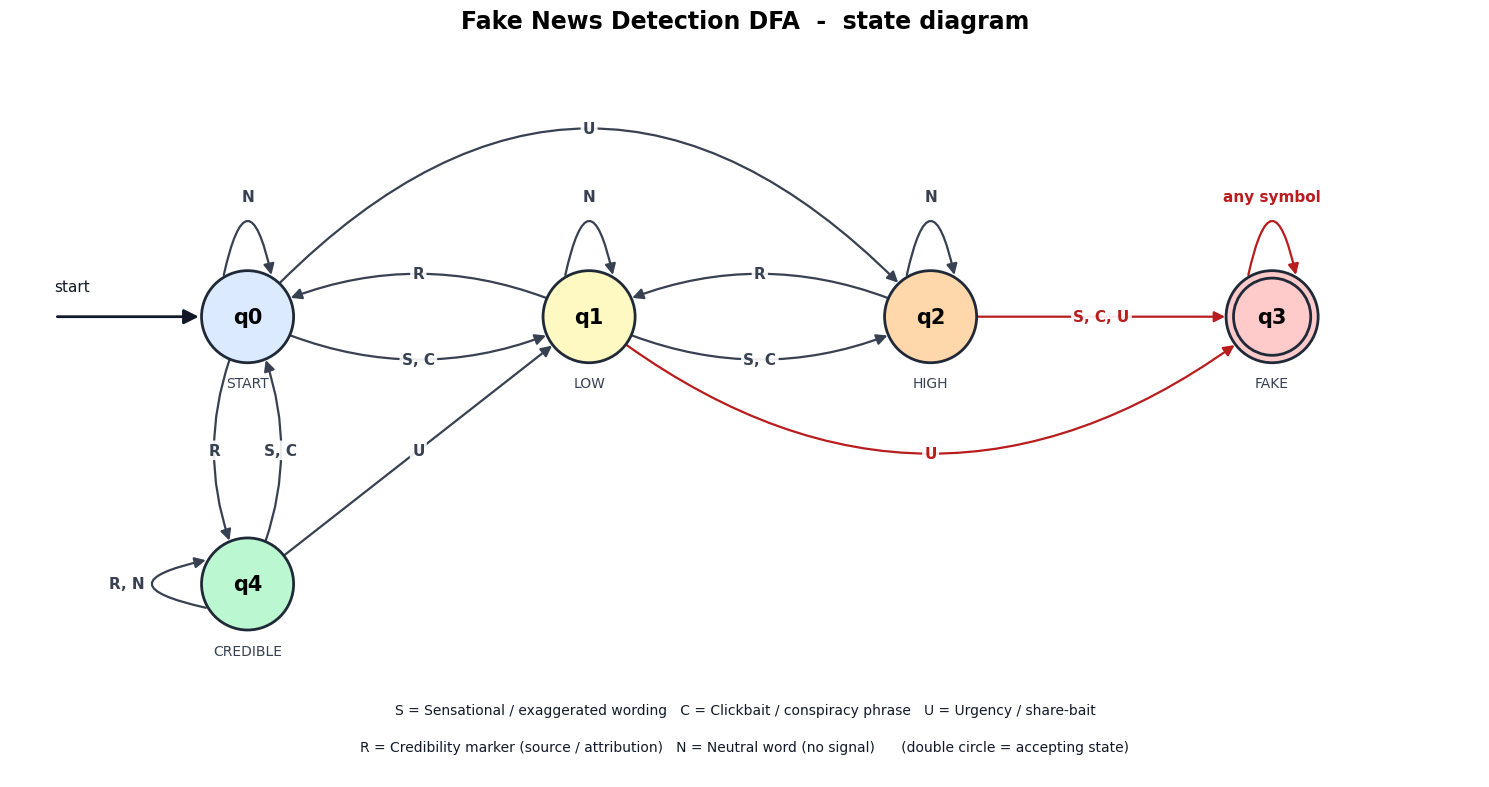

In [10]:
draw_dfa_diagram(dfa)

## 9. Load the dataset with pandas

`dataset.csv` contains **60 labelled headlines** (30 Fake, 30 Real) with the columns `headline` and `label`.

If you opened this notebook directly from GitHub in Colab, `dataset.csv` is not on the Colab machine yet.
The next cell therefore re-creates it from a copy embedded in the notebook (if you cloned the repository
or uploaded the file, your own copy is used).

In [11]:
# =============================================================================
# SECTION 7: DATASET LOADING AND EVALUATION (pandas)
# =============================================================================
def load_dataset(path) -> pd.DataFrame:
    """Read the labelled headlines CSV with pandas and validate it.

    The file must contain the columns 'headline' and 'label' (Fake / Real).

    Raises:
        FileNotFoundError: if the file does not exist.
        ValueError: if the file is empty, malformed or has wrong labels.
    """
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Dataset file not found: '{path}'.")

    try:
        data = pd.read_csv(path, encoding="utf-8")
    except (pd.errors.EmptyDataError, pd.errors.ParserError, UnicodeDecodeError) as error:
        raise ValueError(f"Could not read '{path}' as a CSV file: {error}") from error

    data.columns = data.columns.str.strip().str.lower()
    missing = {"headline", "label"} - set(data.columns)
    if missing:
        raise ValueError(f"Dataset is missing required column(s): {', '.join(sorted(missing))}.")

    data = data[["headline", "label"]].dropna()
    data["headline"] = data["headline"].astype(str).str.strip()
    data["label"] = data["label"].astype(str).str.strip().str.capitalize()

    bad_labels = sorted(set(data["label"]) - set(LABELS))
    if bad_labels:
        raise ValueError(f"Unknown label(s) in dataset: {bad_labels}. Allowed labels: {list(LABELS)}.")

    data = data.drop_duplicates(subset="headline").reset_index(drop=True)
    if data.empty:
        raise ValueError("The dataset contains no usable rows.")
    return data


def evaluate_dataset(data: pd.DataFrame, dfa: DFA) -> pd.DataFrame:
    """Run the DFA on every dataset headline and compare with the true label.

    Returns a copy of the data with the extra columns:
    'predicted', 'final_state' and 'correct'.
    """
    predicted: List[str] = []
    final_states: List[str] = []
    for headline in data["headline"]:
        try:
            result = detect(headline, dfa)
            predicted.append(result.label)
            final_states.append(result.final_state)
        except InvalidHeadlineError:
            predicted.append("Invalid")    # counted as a wrong prediction
            final_states.append("-")

    results = data.copy()
    results["predicted"] = predicted
    results["final_state"] = final_states
    results["correct"] = results["label"] == results["predicted"]
    return results


def _safe_divide(numerator: float, denominator: float) -> float:
    """Division that returns 0.0 instead of raising ZeroDivisionError."""
    return numerator / denominator if denominator else 0.0


def format_evaluation(results: pd.DataFrame) -> str:
    """Summarise accuracy, confusion matrix and precision / recall for 'Fake'."""
    total = len(results)
    correct = int(results["correct"].sum())

    matrix = (
        pd.crosstab(results["label"], results["predicted"])
        .reindex(index=list(LABELS), columns=list(LABELS), fill_value=0)
    )
    true_pos = int(matrix.loc["Fake", "Fake"])
    false_pos = int(matrix.loc["Real", "Fake"])
    false_neg = int(matrix.loc["Fake", "Real"])
    precision = _safe_divide(true_pos, true_pos + false_pos)
    recall = _safe_divide(true_pos, true_pos + false_neg)
    f1_score = _safe_divide(2 * precision * recall, precision + recall)

    lines = [
        "=" * REPORT_WIDTH,
        "DATASET EVALUATION",
        "=" * REPORT_WIDTH,
        f"Total headlines : {total}  ({int((results['label'] == 'Fake').sum())} Fake, "
        f"{int((results['label'] == 'Real').sum())} Real)",
        f"Correct         : {correct}",
        f"Accuracy        : {_safe_divide(correct, total) * 100:.2f} %",
        "",
        "Confusion matrix (rows = actual, columns = predicted):",
        matrix.to_string(),
        "",
        f"Fake class -> precision: {precision:.2f}   recall: {recall:.2f}   F1-score: {f1_score:.2f}",
    ]

    wrong = results[~results["correct"]]
    if not wrong.empty:
        lines.append("")
        lines.append("Misclassified headlines:")
        for _, row in wrong.iterrows():
            lines.append(f"  - [{row['label']} -> {row['predicted']}, state {row['final_state']}] {row['headline']}")
    lines.append("=" * REPORT_WIDTH)
    return "\n".join(lines)

In [12]:
DATASET_PATH = Path("dataset.csv")

EMBEDDED_CSV = """headline,label
"SHOCKING: Drinking hot water cures cancer in 3 days, doctors hate this secret!",Fake
Government announces new scholarship scheme for rural engineering students,Real
"Government hiding the truth about 5G towers causing mind control, wake up!",Fake
"RBI keeps repo rate unchanged, says inflation remains within target range",Real
Unbelievable! Scientists confirm miracle fruit melts belly fat overnight,Fake
ISRO confirms successful launch of earth observation satellite,Real
Share this before it's deleted: banks will freeze all accounts tomorrow,Fake
Researchers at IIT Madras develop low-cost water purification filter,Real
You won't believe what the mainstream media is hiding about this 100% natural cure,Fake
"Monsoon to reach Kerala by first week of June, weather department reports",Real
"Bombshell: Big Pharma cover-up exposed, millions of vaccines are poison",Fake
"Stock market closes higher as IT shares rally, according to exchange data",Real
Urgent! Forward this message to 10 friends or your phone will explode tonight,Fake
Study published in Nature links regular exercise to better sleep quality,Real
"Miracle herb guaranteed to cure diabetes instantly, hospitals don't want you to know",Fake
"Delhi Metro adds new stations on Blue Line extension, officials said",Real
"Illuminati mind control exposed: aliens run the world, wake up people!",Fake
Ministry of Education releases guidelines for online examinations,Real
"Horrifying truth: eating bananas at night is deadly poison, share with everyone",Fake
India wins the third cricket match by five wickets,Real
"Deep state hoax: moon landing was staged in a Hollywood studio, hidden truth revealed",Fake
University announces revised timetable for semester examinations,Real
"Doctors hate her: one weird trick erases wrinkles overnight, stunning results!",Fake
WHO report shows decline in global malaria cases over the last decade,Real
"Free iPhone for everyone! Click and share this now, offer ends tonight",Fake
Local bakery wins national award for best traditional sweets,Real
"5G chemtrails are controlling your mind, mainstream media won't tell you",Fake
"Heavy rainfall expected in Chennai over the weekend, forecast says",Real
Jaw-dropping: Man survives 40 days without food thanks to this secret herb!,Fake
City council approves budget for new public library and parks,Real
"Secret video shows city mayor taking bribes, mainstream media silent, share now!",Fake
"Scientists discover new species of frog in Western Ghats, study published",Real
The truth about vitamin pills: they are a 100% scam and Big Pharma knows it,Fake
"Electric vehicle sales rise by 30 percent in the last quarter, data shows",Real
"Miracle drink guaranteed to melt fat instantly, no exercise needed",Fake
High Court dismisses petition against new road project,Real
"Wake up! New world order plans to ban cash by Friday, spread the word",Fake
Tech company launches budget smartphone with 5000 mAh battery,Real
Must watch: shocking video the government doesn't want you to see,Fake
"Farmers receive crop insurance payout after delayed monsoon, statement says",Real
"Lemon water 100% cures all diseases, doctors hate this simple secret",Fake
Airline cancels flights due to heavy fog at northern airports,Real
"Unbelievable discovery: ancient pyramid hides a secret machine, mind-blowing!",Fake
Health ministry advises citizens to get seasonal flu vaccination,Real
"Hoax or truth? Illuminati symbol found on new currency note, you won't believe it",Fake
Students build solar-powered robot for national science fair,Real
"Tell everyone: tap water in the city is poisoned, authorities are covering it up",Fake
Police arrest two suspects in connection with the mobile phone theft case,Real
"Banned video exposes how banks steal your money, share before they delete it",Fake
Parliament passes bill on data protection after long debate,Real
"Miracle cure discovered! Cancer gone overnight, Big Pharma furious",Fake
"Shocking rise in fuel prices worries commuters, officials say",Real
"Eat this fruit and lose 10 kg in a week guaranteed, secret finally exposed",Fake
"Secret ballot election held peacefully in student union polls, commission reports",Real
"Urgent: Facebook will start charging users next week, forward this to keep your account free",Fake
"Miracle recovery: patient discharged after successful heart surgery, hospital statement says",Real
"Horrifying: new world order microchips hidden in vaccines, wake up and share this",Fake
Survey finds 62 percent of graduates prefer hybrid work,Real
Flat Earth proof exposed! Mainstream media hides the hidden truth about space,Fake
New bridge opens to traffic after two years of construction,Real
"""

if DATASET_PATH.exists():
    print(f"Found '{DATASET_PATH}' - using it.")
else:
    DATASET_PATH.write_text(EMBEDDED_CSV, encoding="utf-8")
    print(f"'{DATASET_PATH}' not found - created it from the copy embedded in this notebook.")

Found 'dataset.csv' - using it.


In [13]:
data = load_dataset(DATASET_PATH)
print(f"Loaded {len(data)} headlines.")
print(data["label"].value_counts().to_string())
data.head(10)

Loaded 60 headlines.
label
Fake    30
Real    30


,headline,label
0,SHOCKING: Drinking hot water cures cancer in 3...,Fake
1,Government announces new scholarship scheme fo...,Real
2,Government hiding the truth about 5G towers ca...,Fake
3,"RBI keeps repo rate unchanged, says inflation ...",Real
4,Unbelievable! Scientists confirm miracle fruit...,Fake
5,ISRO confirms successful launch of earth obser...,Real
6,Share this before it's deleted: banks will fre...,Fake
7,Researchers at IIT Madras develop low-cost wat...,Real
8,You won't believe what the mainstream media is...,Fake
9,"Monsoon to reach Kerala by first week of June,...",Real


## 10. Evaluate the DFA on the dataset

Every headline is run through the DFA and the predicted label is compared with the true label.

> **Important:** the sample dataset is small and was written together with the keyword lexicon, so a very high score
> here only shows that the DFA logic works as designed - it is **not** a claim about real-world accuracy.

In [14]:
results = evaluate_dataset(data, dfa)
print(format_evaluation(results))

DATASET EVALUATION
Total headlines : 60  (30 Fake, 30 Real)
Correct         : 60
Accuracy        : 100.00 %

Confusion matrix (rows = actual, columns = predicted):
predicted  Fake  Real
label                
Fake         30     0
Real          0    30

Fake class -> precision: 1.00   recall: 1.00   F1-score: 1.00


In [15]:
# Which final DFA state does each class end in?
display(pd.crosstab(results["label"], results["final_state"], rownames=["actual"], colnames=["final state"]))
results.head(10)

final state,q0,q3,q4
actual,,,
Fake,0,30,0
Real,9,0,21


,headline,label,predicted,final_state,correct
0,SHOCKING: Drinking hot water cures cancer in 3...,Fake,Fake,q3,True
1,Government announces new scholarship scheme fo...,Real,Real,q4,True
2,Government hiding the truth about 5G towers ca...,Fake,Fake,q3,True
3,"RBI keeps repo rate unchanged, says inflation ...",Real,Real,q4,True
4,Unbelievable! Scientists confirm miracle fruit...,Fake,Fake,q3,True
5,ISRO confirms successful launch of earth obser...,Real,Real,q4,True
6,Share this before it's deleted: banks will fre...,Fake,Fake,q3,True
7,Researchers at IIT Madras develop low-cost wat...,Real,Real,q4,True
8,You won't believe what the mainstream media is...,Fake,Fake,q3,True
9,"Monsoon to reach Kerala by first week of June,...",Real,Real,q4,True


## 11. Sample outputs - full explanation for two headlines

For each headline the output shows the **detected keywords**, the **state transitions**, the **final DFA state**
and only then the **prediction**.

In [16]:
for headline in SAMPLE_HEADLINES[:2]:
    print_report(detect(headline, dfa), dfa)
    print()

HEADLINE: SHOCKING secret cure exposed! Share this before it's deleted
STEP 1 - Detected keywords
  1. "shocking"  ->  S  (Sensational / exaggerated wording)
  2. "secret"  ->  S  (Sensational / exaggerated wording)
  3. "exposed"  ->  S  (Sensational / exaggerated wording)
  4. "!"  ->  S  (Sensational / exaggerated wording)
  5. "share this"  ->  U  (Urgency / share-bait)
  6. "before its deleted"  ->  U  (Urgency / share-bait)

STEP 2 - DFA state transitions (start state = q0)
  [ 1] q0 --S--> q1    (read "shocking")
  [ 2] q1 --S--> q2    (read "secret")
  [ 4] q2 --S--> q3    (read "exposed")
  [ 5] q3 --S--> q3    (read "!")
  [ 6] q3 --U--> q3    (read "share this")
  [ 7] q3 --U--> q3    (read "before its deleted")
  ...  1 neutral word(s) caused self-loops (hidden; use verbose mode to show)

STEP 3 - Final DFA state
  Final state     : q3
  Meaning         : FAKE - suspicion threshold reached (accepting, absorbing)
  Accepting state : YES
--------------------------------------

### An interesting case: credibility markers cancel suspicious words

*"Shocking rise in onion prices worries shoppers, ministry reports"* contains a sensational word (`shocking`),
but the credibility marker `ministry` / `reports` pulls the DFA back, so it is **not** flagged.

In [17]:
print_report(detect(SAMPLE_HEADLINES[4], dfa), dfa, show_neutral=True)   # show_neutral=True lists every word

HEADLINE: Shocking rise in onion prices worries shoppers, ministry reports
STEP 1 - Detected keywords
  1. "shocking"  ->  S  (Sensational / exaggerated wording)
  2. "ministry"  ->  R  (Credibility marker (source / attribution))
  3. "reports"  ->  R  (Credibility marker (source / attribution))

STEP 2 - DFA state transitions (start state = q0)
  [ 1] q0 --S--> q1    (read "shocking")
  [ 2] q1 --N--> q1    (read "rise")
  [ 3] q1 --N--> q1    (read "in")
  [ 4] q1 --N--> q1    (read "onion")
  [ 5] q1 --N--> q1    (read "prices")
  [ 6] q1 --N--> q1    (read "worries")
  [ 7] q1 --N--> q1    (read "shoppers")
  [ 8] q1 --R--> q0    (read "ministry")
  [ 9] q0 --R--> q4    (read "reports")

STEP 3 - Final DFA state
  Final state     : q4
  Meaning         : CREDIBLE - credibility marker seen
  Accepting state : NO
------------------------------------------------------------------------
PREDICTION: REAL   (DFA ended in non-accepting state q4)


### Summary of all sample headlines

In [18]:
rows = []
for headline in SAMPLE_HEADLINES:
    result = detect(headline, dfa)
    rows.append({
        "headline": headline,
        "keywords": ", ".join(f"{t.text}:{t.symbol}" for t in result.keywords) or "-",
        "final state": result.final_state,
        "prediction": result.label,
    })
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(rows)

,headline,keywords,final state,prediction
0,SHOCKING secret cure exposed! Share this before it's deleted,"shocking:S, secret:S, exposed:S, !:S, share this:U, before its deleted:U",q3,Fake
1,"Government announces new metro line, officials said","announces:R, officials:R, said:R",q4,Real
2,Researchers publish study on air pollution in Indian cities,"researchers:R, study:R",q4,Real
3,"Miracle weight loss pill guaranteed to work, doctors hate it","miracle:S, guaranteed:S, doctors hate:C",q3,Fake
4,"Shocking rise in onion prices worries shoppers, ministry reports","shocking:S, ministry:R, reports:R",q4,Real
5,Local school wins state level football tournament,-,q0,Real


## 12. Try your own headline

Edit the text in the form field (or the string below) and run the cell.
Invalid input (empty text, only numbers, fewer than 3 words ...) is handled gracefully with a clear message.

In [19]:
#@title Try your own headline { display-mode: "form" }
headline = "SHOCKING secret cure exposed! Share this before it's deleted"  #@param {type:"string"}

try:
    prediction = detect(headline, dfa)
except InvalidHeadlineError as error:
    print(f"[Invalid input] {error}")
else:
    print_report(prediction, dfa)

HEADLINE: SHOCKING secret cure exposed! Share this before it's deleted
STEP 1 - Detected keywords
  1. "shocking"  ->  S  (Sensational / exaggerated wording)
  2. "secret"  ->  S  (Sensational / exaggerated wording)
  3. "exposed"  ->  S  (Sensational / exaggerated wording)
  4. "!"  ->  S  (Sensational / exaggerated wording)
  5. "share this"  ->  U  (Urgency / share-bait)
  6. "before its deleted"  ->  U  (Urgency / share-bait)

STEP 2 - DFA state transitions (start state = q0)
  [ 1] q0 --S--> q1    (read "shocking")
  [ 2] q1 --S--> q2    (read "secret")
  [ 4] q2 --S--> q3    (read "exposed")
  [ 5] q3 --S--> q3    (read "!")
  [ 6] q3 --U--> q3    (read "share this")
  [ 7] q3 --U--> q3    (read "before its deleted")
  ...  1 neutral word(s) caused self-loops (hidden; use verbose mode to show)

STEP 3 - Final DFA state
  Final state     : q3
  Meaning         : FAKE - suspicion threshold reached (accepting, absorbing)
  Accepting state : YES
--------------------------------------

### Invalid input is handled gracefully

In [20]:
for bad_input in ["", "   ", "12345 !!!", "Hi", None]:
    try:
        detect(bad_input, dfa)
    except InvalidHeadlineError as error:
        print(f"Input {bad_input!r:>12}  ->  [Invalid input] {error}")

Input           ''  ->  [Invalid input] The headline is empty. Please type a news headline.
Input        '   '  ->  [Invalid input] The headline is empty. Please type a news headline.
Input  '12345 !!!'  ->  [Invalid input] The headline must contain English letters, not only digits or symbols.
Input         'Hi'  ->  [Invalid input] The headline is too short (1 word(s)). Please enter at least 3 words.
Input         None  ->  [Invalid input] The headline must be text.


## 13. Interactive mode (optional)

Run this cell to type headlines one after another. Type `quit` to stop.

In [ ]:
interactive_mode(dfa)

## 14. Conclusion and limitations

**What we did:** we modelled headline analysis as a DFA, where every word moves the machine between five states
and the headline is called *Fake* only when the machine finishes in the accepting state `q3`.

**Limitations (be honest in your viva!)**

* A DFA has **finite memory** and no understanding of meaning - it only counts weighted signals, so true but
  sensational headlines can be flagged and subtle fake news without trigger words is missed.
* The lexicon is hand-written and English-only; the dataset is tiny.
* Real fake-news detection needs NLP / machine learning and fact checking - this project demonstrates the
  *automata-theory concept*, not a production detector.

**Possible extensions:** larger lexicon, an NFA-to-DFA conversion demo, regular-expression based patterns,
comparison with a machine-learning baseline (e.g. TF-IDF + logistic regression).